In [24]:

import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

df = pd.read_csv('indian_tech_jobs_2026.csv')

pattern = 'data|analyst|analytics|scientist|machine learning|ai'
data_retalted_titles = df[df['job_title'].str.contains(pattern, case=False, na=False)]
               

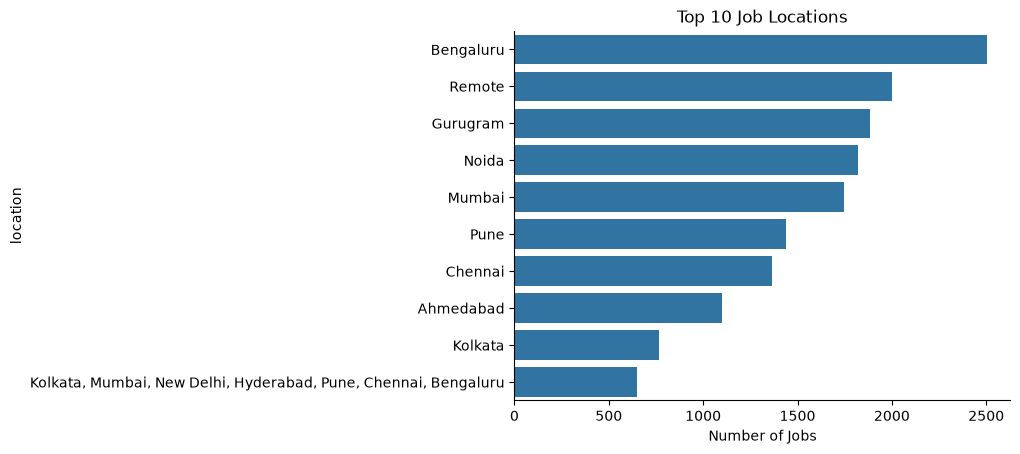

In [25]:
df['location'].value_counts().head(10).to_frame()

sns.countplot(
    data=df, 
    y='location', 
    order=df['location'].value_counts().head(10).index
)
plt.title('Top 10 Job Locations')
plt.xlabel('Number of Jobs')
sns.despine()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_16228\2680470145.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['job_work_from_home'] = (df['work_mode'] == 'Remote') | df['job_description'].str.contains(
C:\Users\Admin\AppData\Local\Temp\ipykernel_16228\2680470145.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['job_degree_req'] = df['job_description'].str.contains(
C:\Users\Admin\AppData\Local\Temp\ipykernel_16228\2680470145.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['job_health_insurance'] = df['job_description'].str.contains(


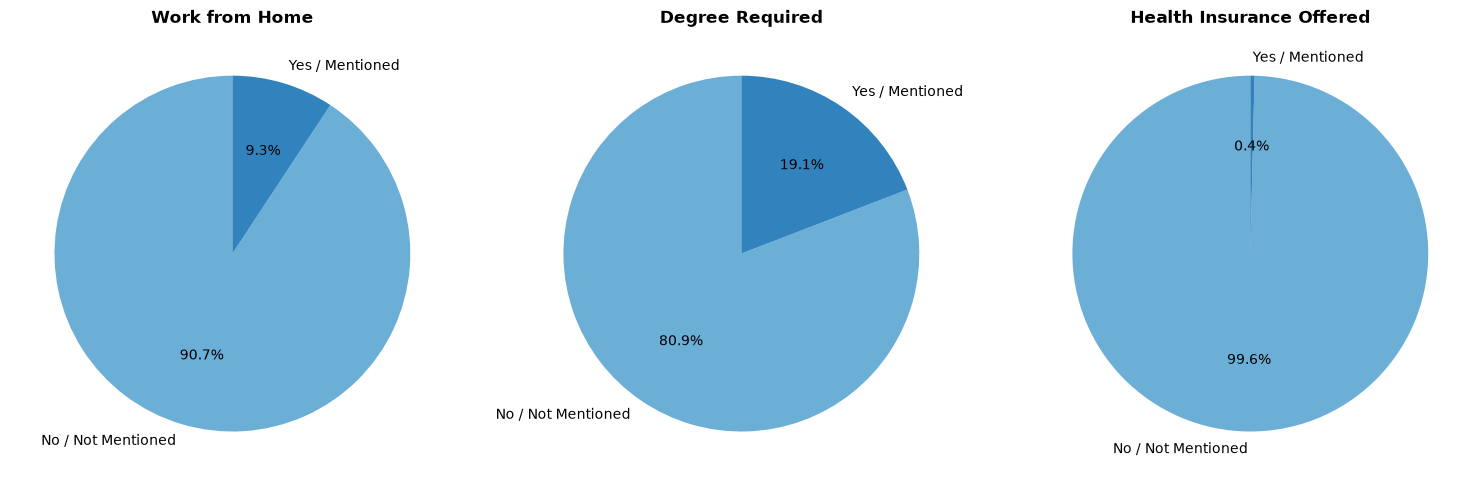

In [33]:
df['job_work_from_home'] = (df['work_mode'] == 'Remote') | df['job_description'].str.contains(
    r'\b(work from home|wfh|remote)\b', case=False, na=False
)

df['job_degree_req'] = df['job_description'].str.contains(
    r'\b(degree|bachelor|b\.?tech|b\.?e|m\.?tech|mca|bca|graduate|graduation|master)\b', 
    case=False, 
    na=False
)

df['job_health_insurance'] = df['job_description'].str.contains(
    r'\b(health insurance|medical insurance|mediclaim|health benefits|insurance)\b', 
    case=False, 
    na=False
)

# 2. Dictionary mapping columns to plot titles
dict_column = {
    'job_work_from_home': 'Work from Home',
    'job_degree_req': 'Degree Required',
    'job_health_insurance': 'Health Insurance Offered'
}

# 3. Create Pie Charts
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, (column, title) in enumerate(dict_column.items()):
    counts = df[column].value_counts().sort_index()  # sorts False (0) then True (1)
    
    # Map index booleans to clean labels
    labels = ['No / Not Mentioned' if not idx else 'Yes / Mentioned' for idx in counts.index]
    
    ax[i].pie(
        counts, 
        labels=labels, 
        autopct='%1.1f%%', 
        startangle=90,
        colors=['#6baed6', '#3182bd'] if len(counts) == 2 else ['#6baed6']
    )
    ax[i].set_title(title, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

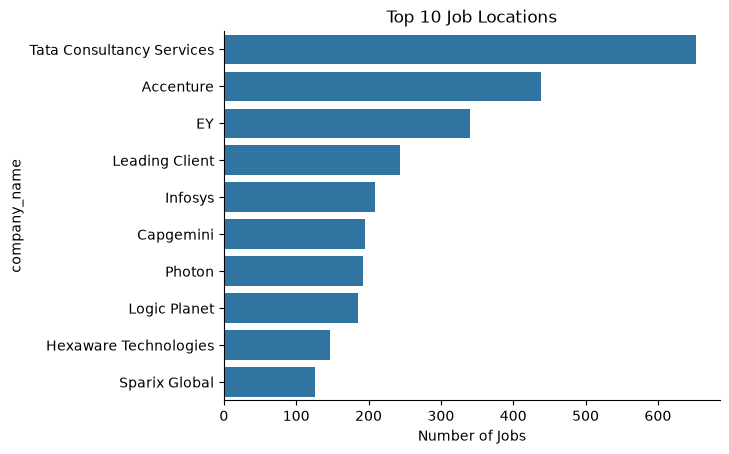

In [34]:
df['company_name'].value_counts().head(10).to_frame()

sns.countplot(
    data=df, 
    y='company_name', 
    order=df['company_name'].value_counts().head(10).index
)
plt.title('Top 10 Job Locations')
plt.xlabel('Number of Jobs')
sns.despine()
plt.show()